# 06. Spatial structure and prioritisation

Displays outputs of `src/spatial_mining.py` and `src/prioritization.py`.

In [1]:
import os, sys
from pathlib import Path
ROOT = Path('..').resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, Markdown, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

## 1. Distance decay of Moran's I

,k_neighbors,mean_neighbor_distance_m,morans_i,z_score,p_value
0,3,162.4824,0.2788,27.3387,0.001
1,5,215.9884,0.2444,30.8200,0.001
2,7,261.9850,0.2234,33.3593,0.001
3,10,321.6870,0.2043,36.7727,0.001
4,15,405.2898,0.1888,41.2512,0.001
5,20,477.0471,0.1792,45.4339,0.001


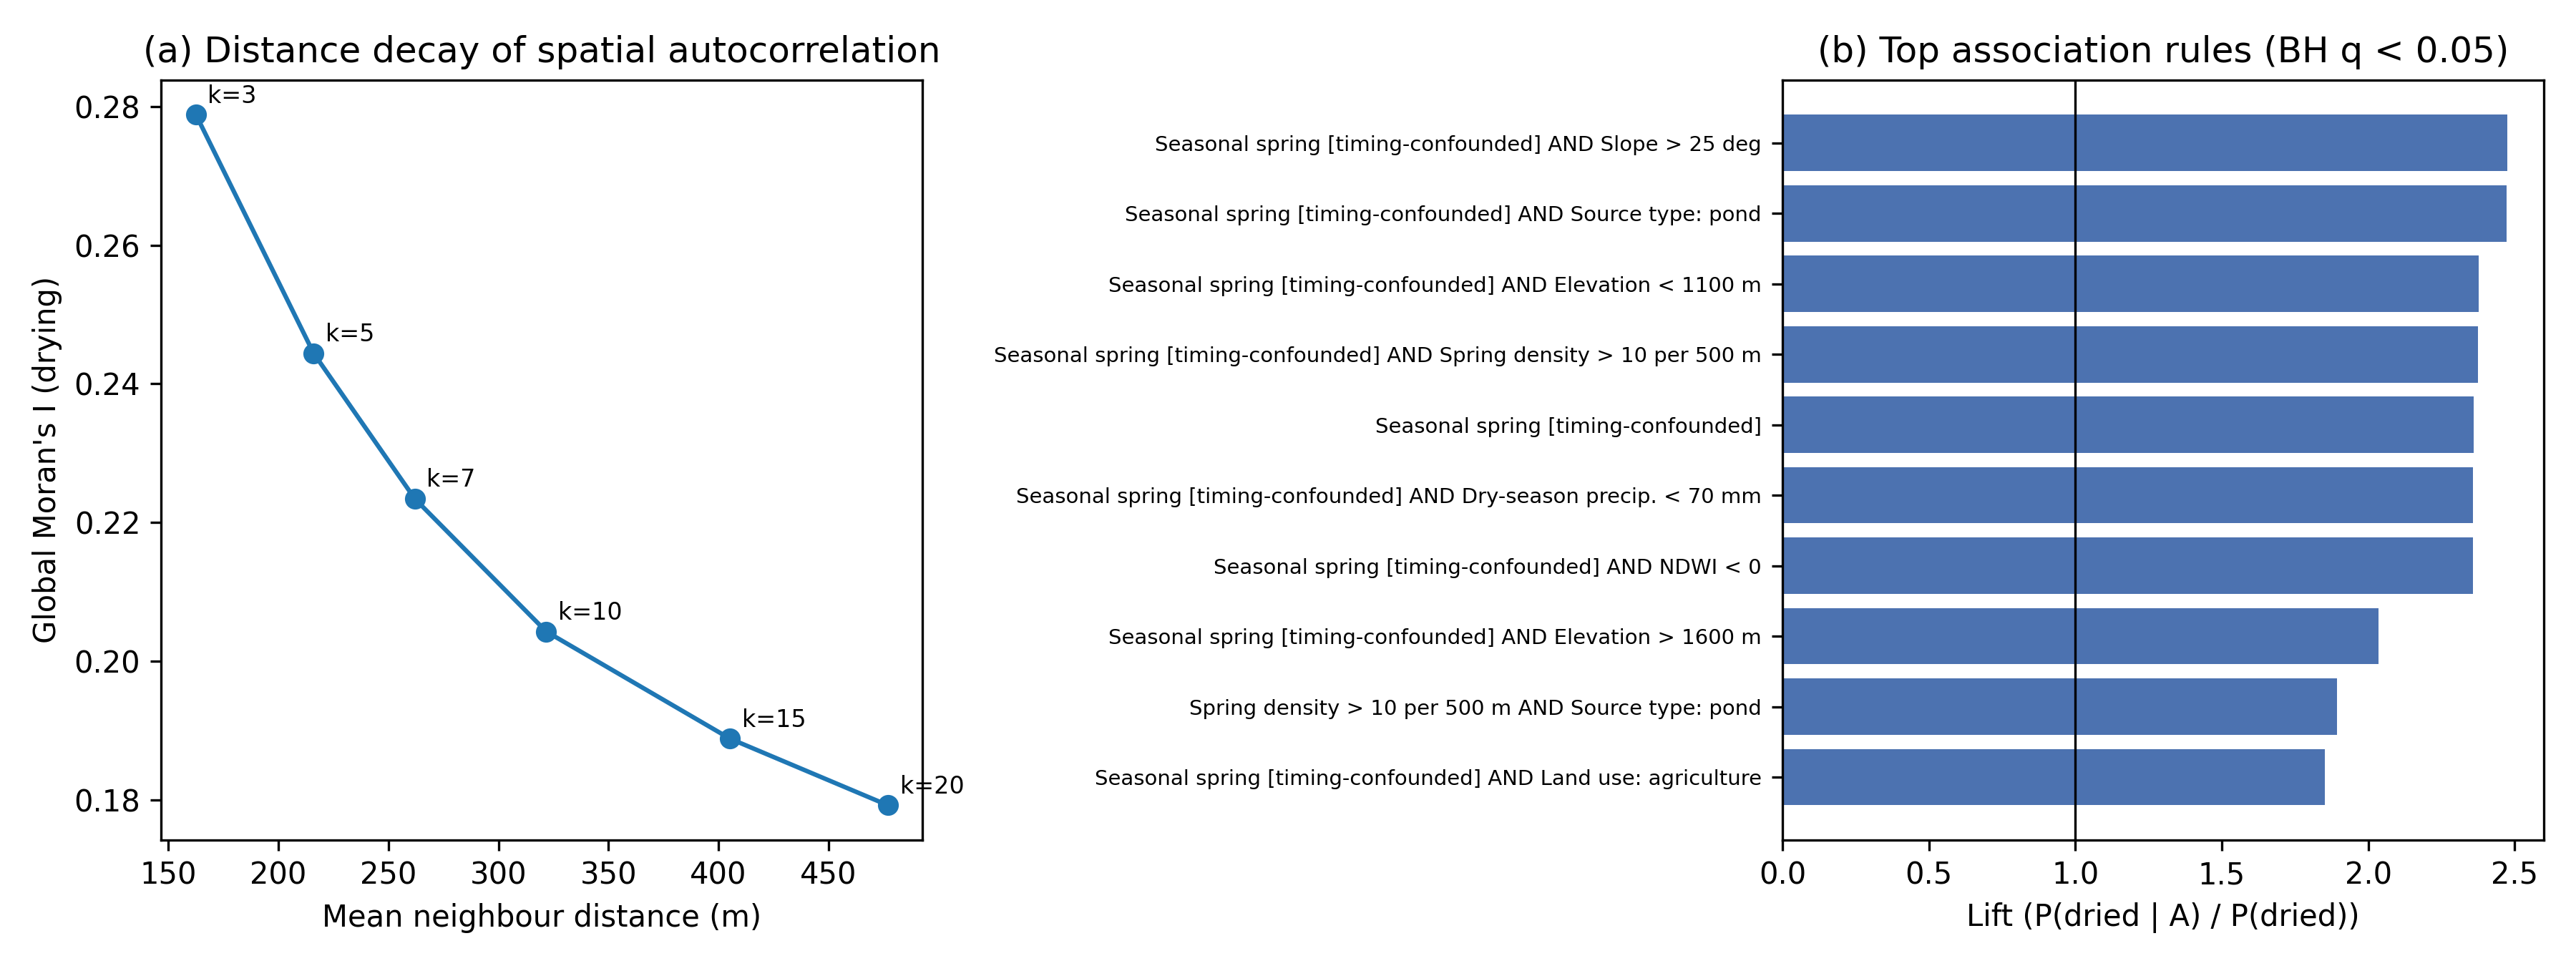

In [2]:
display(pd.read_csv('results/metrics/spatial_autocorrelation_distance_decay.csv').round(4))
display(Image('results/figures/spatial_mining_diagnostics.png'))

## 2. LISA clusters (BH-FDR q < 0.05)

,cluster,n_springs_fdr_q<0.05,n_springs_uncorrected_p<0.05
0,Not significant,5564,5120
1,High-High (dried cluster),95,354
2,Low-High (active among dried),30,215


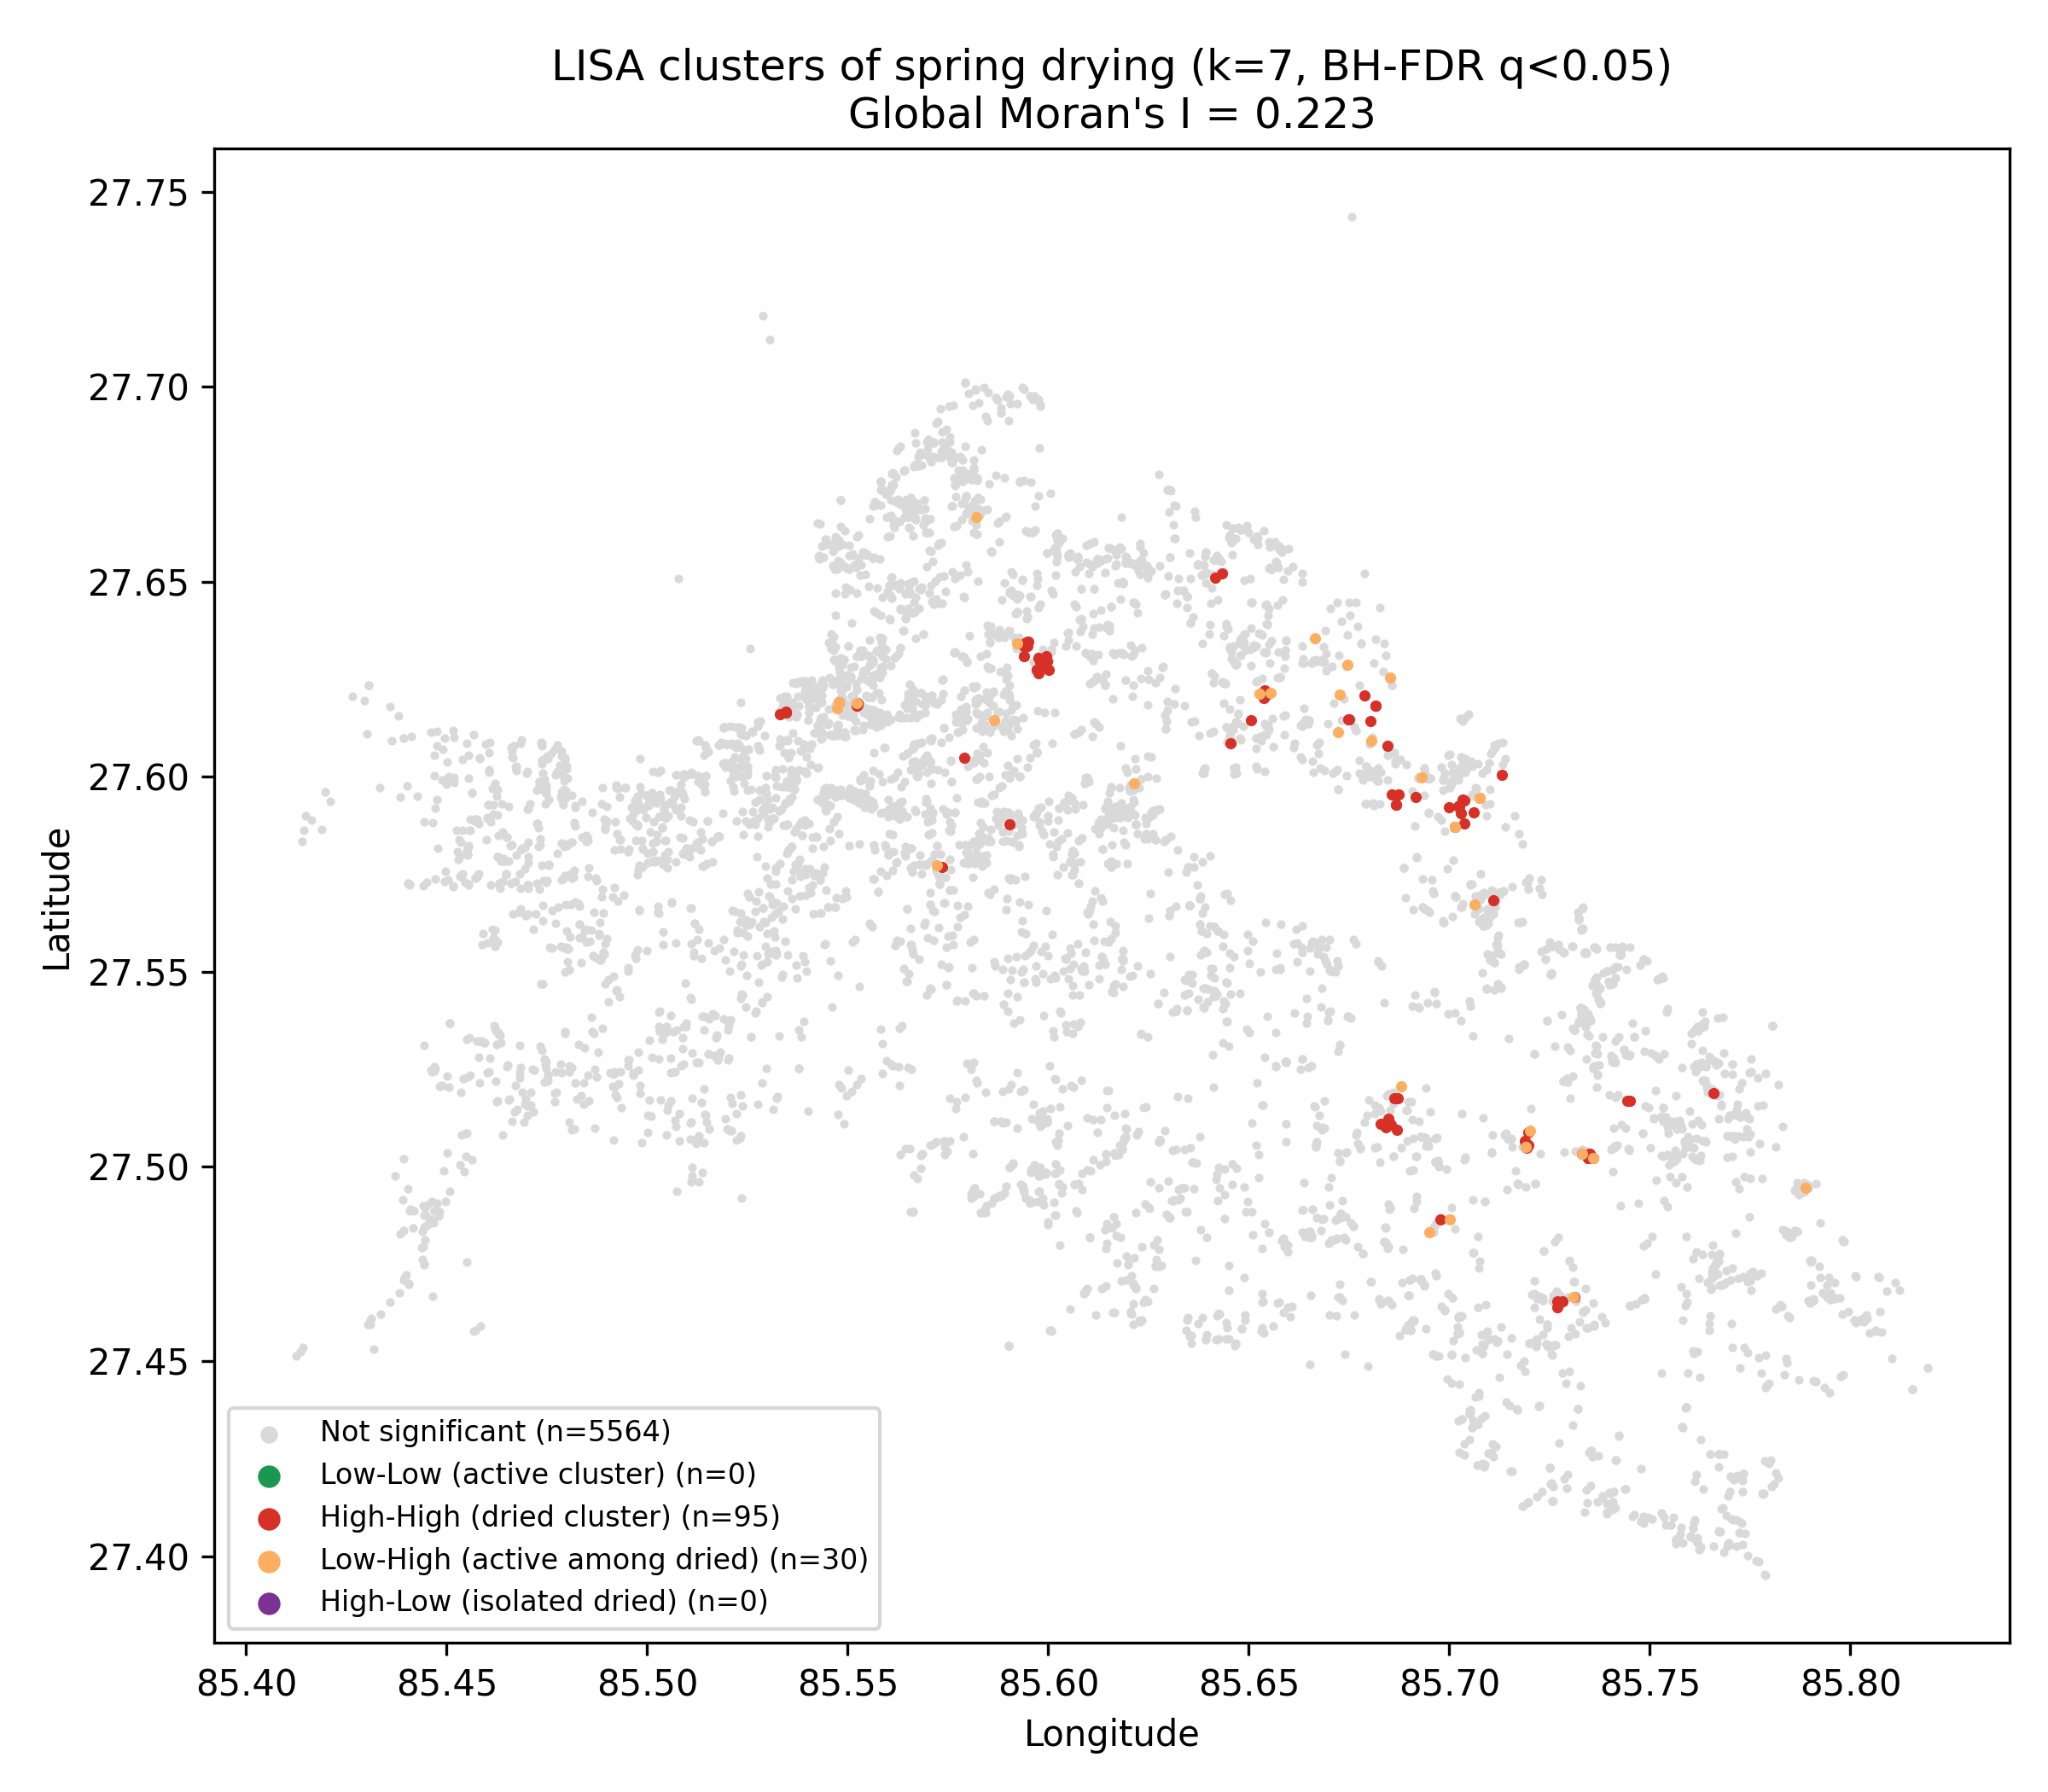

In [3]:
display(pd.read_csv('results/metrics/lisa_cluster_summary.csv'))
display(Image('results/figures/lisa_cluster_map.png'))

## 3. Association rules (Fisher exact test, BH-FDR)
Rules involving seasonality are flagged: the survey ran mostly in the dry season, so a seasonal spring may be recorded as dried because of timing.

In [4]:
display(pd.read_csv('results/metrics/association_rules_desiccation.csv').head(15).round(4))

,antecedent,n_antecedent,n_dried,support,confidence,lift,odds_ratio,p_value,q_value_bh
0,Seasonal spring [timing-confounded] AND Slope ...,281,186,0.0327,0.6619,2.4758,5.9734,0.0,0.0
1,Seasonal spring [timing-confounded] AND Source...,239,158,0.0278,0.6611,2.4727,5.8490,0.0,0.0
2,Seasonal spring [timing-confounded] AND Elevat...,203,129,0.0227,0.6355,2.3768,5.1270,0.0,0.0
3,Seasonal spring [timing-confounded] AND Spring...,548,348,0.0612,0.6350,2.3752,5.8860,0.0,0.0
4,Seasonal spring [timing-confounded],930,587,0.1032,0.6312,2.3608,7.0086,0.0,0.0
5,Seasonal spring [timing-confounded] AND Dry-se...,925,583,0.1025,0.6303,2.3574,6.9532,0.0,0.0
6,Seasonal spring [timing-confounded] AND NDWI < 0,925,583,0.1025,0.6303,2.3574,6.9532,0.0,0.0
7,Seasonal spring [timing-confounded] AND Elevat...,193,105,0.0185,0.5440,2.0349,3.4380,0.0,0.0
8,Spring density > 10 per 500 m AND Source type:...,336,170,0.0299,0.5060,1.8924,3.0336,0.0,0.0
9,Seasonal spring [timing-confounded] AND Land u...,196,97,0.0171,0.4949,1.8511,2.7997,0.0,0.0


## 4. Spring Priority Index (active springs only)
$\mathrm{SPI}_i = \mathrm{pct}(	ext{susceptibility}_i) 	imes \mathrm{pct}(	ext{households}_i)$ — susceptibility is the out-of-fold predicted probability from the best model (spatial CV), averaged over seeds. Household fields exist only for active springs (survey skip logic).

In [5]:
display(pd.read_csv('results/metrics/priority_index_sensitivity.csv').T)
display(pd.read_csv('results/tables/municipality_priority_summary.csv').round(3))
display(pd.read_csv('results/tables/top_500_priority_active_springs.csv').head(10).round(3))

,0
susceptibility_model,HydroBoost-GAT
model_mean_roc_auc,0.640951
n_seeds_averaged,5
n_active_springs_ranked,3206
n_active_springs_missing_households,962
spearman_SPI_vs_susceptibility,0.707462
spearman_SPI_vs_exposure,0.656229
top500_overlap_with_susceptibility_only_top500,0.528


,municipality,total_sources,dried,drying_rate,active_ranked,mean_susceptibility,households_dependent,in_top_500
0,Bethanchownk,385,74,0.192,243,0.237,7461.0,1
1,Dhulikhel,1174,338,0.288,633,0.428,7455.0,68
2,Namobuudha,478,96,0.201,324,0.472,9465.0,100
3,Panauti,880,83,0.094,664,0.284,15815.0,9
4,Panchkhal,1067,426,0.399,549,0.498,12589.0,151
5,Roshi RM,969,211,0.218,492,0.399,8464.0,46
6,Temal,736,293,0.398,301,0.570,5586.0,125


,id,SPI_rank,municipality,ward,latitude,longitude,susceptibility,hh_dependent_total,hh_dependent_exclusive,fetch_time_minutes,susceptibility_pct,exposure_pct,SPI
0,40,1,Namobuudha,8,27.545,85.629,0.685,103.0,NaN,NaN,0.980,0.977,0.957
1,2775,2,Temal,5,27.518,85.730,0.652,500.0,500.0,25.0,0.959,0.998,0.956
2,5145,3,Panchkhal,12,27.621,85.653,0.663,160.0,70.0,5.0,0.967,0.987,0.954
3,458,4,Namobuudha,3,27.584,85.629,0.671,100.0,NaN,2.0,0.971,0.971,0.944
4,3932,5,Dhulikhel,8,27.610,85.571,0.654,106.0,106.0,40.0,0.960,0.978,0.939
5,454,6,Namobuudha,3,27.588,85.622,0.736,60.0,NaN,NaN,0.992,0.944,0.936
6,3917,7,Dhulikhel,11,27.589,85.602,0.750,50.0,50.0,5.0,0.995,0.922,0.917
7,3903,8,Dhulikhel,6,27.618,85.550,0.684,55.0,5.0,NaN,0.979,0.937,0.917
8,5472,9,Panchkhal,9,27.629,85.655,0.670,60.0,20.0,5.0,0.970,0.944,0.915
9,4318,10,Dhulikhel,7,27.613,85.556,0.733,50.0,10.0,NaN,0.990,0.922,0.913
